In [1]:
!pip -q install kagglehub

In [26]:
import os
import re
import numpy as np
import pandas as pd
import tensorflow as tf
import kagglehub
import matplotlib.pyplot as plt
import textwrap

from collections import Counter
from pathlib import Path
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display

print("TensorFlow version:", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))


TensorFlow version: 2.21.0
GPU available: True


In [27]:
dataset_path = kagglehub.dataset_download("adityajn105/flickr8k")

print("Dataset downloaded to:")
print(dataset_path)


Using Colab cache for faster access to the 'flickr8k' dataset.
Dataset downloaded to:
/kaggle/input/flickr8k


In [28]:

from pathlib import Path

ROOT = Path(dataset_path)
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}

caption_file = None
image_dir = None

for path in ROOT.rglob("*"):
    if path.is_file() and path.name.lower() in {
        "captions.txt", "captions.csv"
    }:
        try:
            preview = pd.read_csv(path, nrows=5)
            columns = {
                str(c).strip().lower()
                for c in preview.columns
            }

            if {"image", "caption"}.issubset(columns):
                caption_file = path
                break
        except Exception:
            pass

image_candidates = []

for path in ROOT.rglob("*"):
    if path.is_dir():
        count = sum(
            1 for item in path.iterdir()
            if item.is_file()
            and item.suffix.lower() in IMAGE_EXTENSIONS
        )

        if count > 0:
            image_candidates.append((count, path))

if image_candidates:
    image_dir = max(image_candidates, key=lambda x: x[0])[1]

print("Caption file:", caption_file)
print("Image directory:", image_dir)

assert caption_file is not None, (
    "Caption CSV/TXT with image and caption columns was not found."
)
assert image_dir is not None, "Image folder was not found."


Caption file: /kaggle/input/flickr8k/captions.txt
Image directory: /kaggle/input/flickr8k/Images


In [29]:
df = pd.read_csv(caption_file)

df.columns = [str(c).strip().lower() for c in df.columns]
df = df[["image", "caption"]].dropna()

def clean_caption(text):
    text = str(text).lower().strip()
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

captions_dict = {}

for image_name, caption in zip(df["image"], df["caption"]):
    image_name = os.path.basename(str(image_name).strip())
    caption = clean_caption(caption)

    if caption:
        captions_dict.setdefault(image_name, []).append(caption)

available_images = {
    p.name for p in image_dir.iterdir()
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
}

image_names = sorted(
    name for name in captions_dict
    if name in available_images
)

print("Images with captions:", len(image_names))
print(
    "Total captions:",
    sum(len(captions_dict[name]) for name in image_names)
)

assert len(image_names) > 100, (
    "Too few matching images. Check the dataset paths and file format."
)

print("\nExample image:", image_names[0])
print("Example captions:", captions_dict[image_names[0]][:2])


Images with captions: 8091
Total captions: 40455

Example image: 1000268201_693b08cb0e.jpg
Example captions: ['a child in a pink dress is climbing up a set of stairs in an entry way', 'a girl going into a wooden building']


In [30]:

rng = np.random.RandomState(42)

shuffled_names = image_names.copy()
rng.shuffle(shuffled_names)

split_index = int(len(shuffled_names) * 0.90)

train_names = shuffled_names[:split_index]
val_names = shuffled_names[split_index:]

print("Training images:", len(train_names))
print("Validation images:", len(val_names))


Training images: 7281
Validation images: 810


In [31]:

from tensorflow.keras.applications import InceptionV3
from tensorflow.keras.applications.inception_v3 import preprocess_input

IMG_SIZE = 299
FEATURE_BATCH_SIZE = 32

image_encoder = InceptionV3(
    weights="imagenet",
    include_top=False,
    pooling="avg",
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

image_encoder.trainable = False

def load_and_preprocess_image(path):
    image_bytes = tf.io.read_file(path)

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = preprocess_input(image)

    return image

all_image_paths = [
    str(image_dir / name) for name in image_names
]

feature_ds = (
    tf.data.Dataset.from_tensor_slices(all_image_paths)
    .map(
        load_and_preprocess_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )
    .batch(FEATURE_BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

feature_matrix = image_encoder.predict(
    feature_ds,
    verbose=1
).astype("float32")

name_to_row = {
    name: index for index, name in enumerate(image_names)
}

feature_dim = feature_matrix.shape[1]

print("Feature matrix shape:", feature_matrix.shape)
print("Feature dimension:", feature_dim)


253/253 ━━━━━━━━━━━━━━━━━━━━ 52s 169ms/step
Feature matrix shape: (8091, 2048)
Feature dimension: 2048


In [32]:

MIN_WORD_COUNT = 3
MAX_CAPTION_LENGTH = 35

EMBED_DIM = 256
LATENT_DIM = 256

word_counter = Counter(
    word
    for name in train_names
    for caption in captions_dict[name]
    for word in caption.split()
)

vocab_words = sorted(
    word for word, count in word_counter.items()
    if count >= MIN_WORD_COUNT
)

word2idx = {
    "<pad>": 0,
    "<unk>": 1,
    "startseq": 2,
    "endseq": 3
}

for word in vocab_words:
    if word not in word2idx:
        word2idx[word] = len(word2idx)

idx2word = {
    index: word for word, index in word2idx.items()
}

VOCAB_SIZE = len(word2idx)

longest_caption = max(
    len(caption.split()) + 2
    for name in train_names
    for caption in captions_dict[name]
)

MAX_LEN = min(MAX_CAPTION_LENGTH, longest_caption)

print("Vocabulary size:", VOCAB_SIZE)
print("Maximum caption length:", MAX_LEN)


Vocabulary size: 3864
Maximum caption length: 35


In [33]:

def encode_caption(caption):
    words = caption.split()

    tokens = ["startseq"]

    tokens += [
        word if word in word2idx else "<unk>"
        for word in words
    ]

    tokens.append("endseq")

    if len(tokens) > MAX_LEN:
        tokens = tokens[:MAX_LEN]
        tokens[-1] = "endseq"

    return [word2idx[token] for token in tokens]


example_caption = captions_dict[train_names[0]][0]

print("Original:", example_caption)
print("Encoded:", encode_caption(example_caption))


Original: a black and white dog bounds off the ground all feet in the air of a yellow field
Encoded: [2, 4, 327, 74, 3773, 953, 389, 2188, 3425, 1433, 52, 1162, 1638, 3425, 45, 2187, 4, 3849, 1180, 3]


In [34]:

def make_caption_arrays(names):
    feature_rows = []
    decoder_inputs = []
    decoder_targets = []
    sample_weights = []

    steps = MAX_LEN - 1

    for name in names:
        image_row = name_to_row[name]

        for caption in captions_dict[name]:
            sequence = encode_caption(caption)

            input_seq = sequence[:-1]
            target_seq = sequence[1:]

            input_seq = input_seq[:steps]
            target_seq = target_seq[:steps]

            input_seq += [0] * (steps - len(input_seq))
            target_seq += [0] * (steps - len(target_seq))

            weights = [
                1.0 if token != 0 else 0.0
                for token in target_seq
            ]

            feature_rows.append(image_row)
            decoder_inputs.append(input_seq)
            decoder_targets.append(target_seq)
            sample_weights.append(weights)

    return (
        np.asarray(feature_rows, dtype=np.int32),
        np.asarray(decoder_inputs, dtype=np.int32),
        np.asarray(decoder_targets, dtype=np.int32),
        np.asarray(sample_weights, dtype=np.float32)
    )

train_arrays = make_caption_arrays(train_names)
val_arrays = make_caption_arrays(val_names)

print("Training caption sequences:", len(train_arrays[0]))
print("Validation caption sequences:", len(val_arrays[0]))
print("Decoder input shape:", train_arrays[1].shape)
print("Decoder target shape:", train_arrays[2].shape)


Training caption sequences: 36405
Validation caption sequences: 4050
Decoder input shape: (36405, 34)
Decoder target shape: (36405, 34)


In [35]:

BATCH_SIZE = 64

feature_tensor = tf.constant(feature_matrix)

def make_tf_dataset(arrays, training=False):
    rows, decoder_in, decoder_out, weights = arrays

    ds = tf.data.Dataset.from_tensor_slices(
        ((rows, decoder_in), decoder_out, weights)
    )

    if training:
        ds = ds.shuffle(
            min(len(rows), 20000),
            reshuffle_each_iteration=True
        )

    def gather_features(inputs, targets, sample_weights):
        row_ids, token_inputs = inputs

        image_features = tf.gather(feature_tensor, row_ids)

        return (
            (image_features, token_inputs),
            targets,
            sample_weights
        )

    ds = ds.map(
        gather_features,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = make_tf_dataset(train_arrays, training=True)
val_ds = make_tf_dataset(val_arrays, training=False)

print("Training dataset is ready.")


Training dataset is ready.


In [36]:

from tensorflow.keras.layers import (
    Input,
    Dense,
    Dropout,
    Embedding,
    LSTM
)
from tensorflow.keras.models import Model

image_input = Input(
    shape=(feature_dim,),
    name="image_features"
)

image_features = Dropout(0.3)(image_input)

initial_h = Dense(
    LATENT_DIM,
    activation="tanh",
    name="initial_hidden_state"
)(image_features)

initial_c = Dense(
    LATENT_DIM,
    activation="tanh",
    name="initial_cell_state"
)(image_features)

caption_input = Input(
    shape=(MAX_LEN - 1,),
    dtype="int32",
    name="caption_input"
)

embedded = Embedding(
    input_dim=VOCAB_SIZE,
    output_dim=EMBED_DIM,
    mask_zero=True,
    name="word_embedding"
)(caption_input)

embedded = Dropout(0.3)(embedded)

decoder_lstm = LSTM(
    LATENT_DIM,
    return_sequences=True,
    name="decoder_lstm"
)

decoder_output = decoder_lstm(
    embedded,
    initial_state=[initial_h, initial_c]
)

decoder_output = Dropout(0.3)(decoder_output)

word_output = Dense(
    VOCAB_SIZE,
    activation="softmax",
    name="word_prediction"
)(decoder_output)

model = Model(
    inputs=[image_input, caption_input],
    outputs=word_output,
    name="ImageCaptioning_EncoderDecoder"
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    weighted_metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="token_accuracy"
        )
    ]
)

model.summary()


Model: "ImageCaptioning_EncoderDecoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ caption_input       │ (None, 34)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ image_features      │ (None, 2048)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ word_embedding      │ (None, 34, 256)   │    989,184 │ caption_input[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 2048)      │          0 │ image_features[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_7 (Dropout) │ (None, 34, 256)   │          0 │ word_embedding[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ initial_hidden_sta… │ (None, 256)       │    524,544 │ dropout_6[0][0]   │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ initial_cell_state  │ (None, 256)       │    524,544 │ dropout_6[0][0]   │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_lstm (LSTM) │ (None, 34, 256)   │    525,312 │ dropout_7[0][0],  │
│                     │                   │            │ initial_hidden_s… │
│                     │                   │            │ initial_cell_sta… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_8 (Dropout) │ (None, 34, 256)   │          0 │ decoder_lstm[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ word_prediction     │ (None, 34, 3864)  │    993,048 │ dropout_8[0][0]   │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 3,556,632 (13.57 MB)

 Trainable params: 3,556,632 (13.57 MB)

 Non-trainable params: 0 (0.00 B)

In [38]:

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=callbacks
)


Epoch 1/20
569/569 ━━━━━━━━━━━━━━━━━━━━ 18s 32ms/step - loss: 4.3762 - token_accuracy: 0.2574 - val_loss: 3.7767 - val_token_accuracy: 0.3080 - learning_rate: 0.0010
Epoch 2/20
569/569 ━━━━━━━━━━━━━━━━━━━━ 18s 31ms/step - loss: 3.6528 - token_accuracy: 0.3204 - val_loss: 3.4709 - val_token_accuracy: 0.3369 - learning_rate: 0.0010
Epoch 3/20
569/569 ━━━━━━━━━━━━━━━━━━━━ 17s 30ms/step - loss: 3.4147 - token_accuracy: 0.3401 - val_loss: 3.3043 - val_token_accuracy: 0.3509 - learning_rate: 0.0010
Epoch 4/20
569/569 ━━━━━━━━━━━━━━━━━━━━ 17s 30ms/step - loss: 3.2584 - token_accuracy: 0.3526 - val_loss: 3.1949 - val_token_accuracy: 0.3588 - learning_rate: 0.0010
Epoch 5/20
569/569 ━━━━━━━━━━━━━━━━━━━━ 17s 30ms/step - loss: 3.1326 - token_accuracy: 0.3634 - val_loss: 3.1025 - val_token_accuracy: 0.3694 - learning_rate: 0.0010
Epoch 6/20
569/569 ━━━━━━━━━━━━━━━━━━━━ 18s 31ms/step - loss: 3.0345 - token_accuracy: 0.3720 - val_loss: 3.0354 - val_token_accuracy: 0.3764 - learning_rate: 0.0010
Epoc

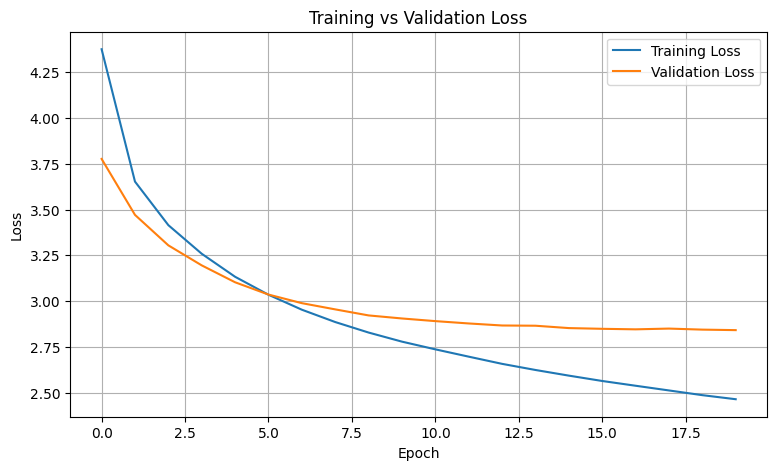

In [39]:
plt.figure(figsize=(9, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


In [40]:

def extract_features(pil_image):
    pil_image = pil_image.convert("RGB").resize(
        (IMG_SIZE, IMG_SIZE)
    )

    image_array = np.asarray(
        pil_image,
        dtype=np.float32
    )

    image_array = preprocess_input(image_array)

    features = image_encoder(
        image_array[None, ...],
        training=False
    )

    return features.numpy()[0].astype("float32")


In [41]:

def extract_features(pil_image):
    pil_image = pil_image.convert("RGB").resize(
        (IMG_SIZE, IMG_SIZE)
    )

    image_array = np.asarray(
        pil_image,
        dtype=np.float32
    )

    image_array = preprocess_input(image_array)

    features = image_encoder(
        image_array[None, ...],
        training=False
    )

    return features.numpy()[0].astype("float32")


In [42]:

def generate_caption(pil_image, beam_size=3):
    image_features = extract_features(pil_image)[None, :]

    start_id = word2idx["startseq"]
    end_id = word2idx["endseq"]
    pad_id = word2idx["<pad>"]
    unk_id = word2idx["<unk>"]

    beams = [([start_id], 0.0)]
    completed = []

    for _ in range(MAX_LEN - 1):
        candidates = []

        for sequence, score in beams:
            if sequence[-1] == end_id:
                completed.append((sequence, score))
                continue

            decoder_input = np.zeros(
                (1, MAX_LEN - 1),
                dtype=np.int32
            )

            decoder_input[0, :len(sequence)] = sequence

            predictions = model(
                [image_features, decoder_input],
                training=False
            ).numpy()

            probabilities = predictions[
                0, len(sequence) - 1
            ].copy()

            probabilities[pad_id] = 0.0
            probabilities[unk_id] = 0.0
            probabilities[start_id] = 0.0

            top_ids = np.argsort(probabilities)[-beam_size:]

            for token_id in top_ids:
                token_id = int(token_id)
                token_prob = float(probabilities[token_id])

                if token_prob <= 0:
                    continue

                new_sequence = sequence + [token_id]
                new_score = score + np.log(token_prob + 1e-12)

                candidates.append((new_sequence, new_score))

        if not candidates:
            break

        candidates.sort(
            key=lambda item: (
                item[1] / (len(item[0]) ** 0.7)
            ),
            reverse=True
        )

        beams = candidates[:beam_size]

        still_active = []

        for sequence, score in beams:
            if sequence[-1] == end_id:
                completed.append((sequence, score))
            else:
                still_active.append((sequence, score))

        beams = still_active

        if not beams:
            break

    final_candidates = completed + beams

    if not final_candidates:
        return "Could not generate a caption."

    best_sequence, _ = max(
        final_candidates,
        key=lambda item: (
            item[1] / (len(item[0]) ** 0.7)
        )
    )

    words = []

    for token_id in best_sequence[1:]:
        if token_id == end_id:
            break

        word = idx2word.get(int(token_id), "")

        if word and word not in {
            "startseq", "endseq", "<pad>", "<unk>"
        }:
            words.append(word)

    caption = " ".join(words).strip()

    if not caption:
        return "Could not generate a caption."

    return caption[0].upper() + caption[1:]


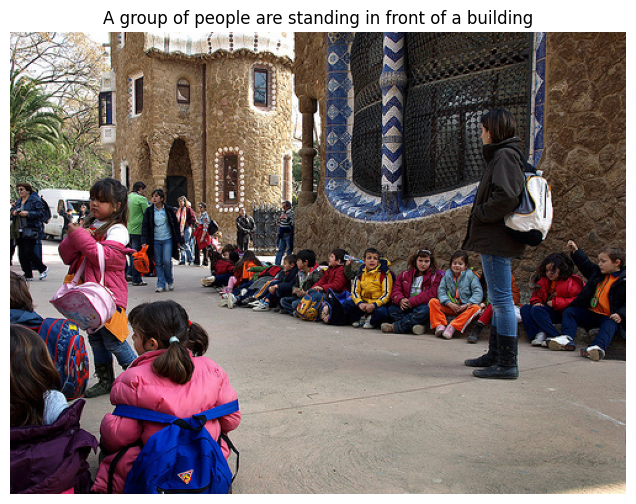

Generated caption:
A group of people are standing in front of a building

Reference captions:
- a girl with a white backpack is standing and smaller children are sitting in a row on the ground
- a lady stands on the street surrounded by school children
- a woman in blue jeans is standing in front of a group of children beside a stone built house
- group of children and some adults gathered outside stone buildings
- many children and some parents are waiting near a decorated castle


In [44]:

test_name = val_names[0]

test_path = image_dir / test_name
test_image = Image.open(test_path).convert("RGB")

predicted_caption = generate_caption(test_image)

plt.figure(figsize=(9, 6))
plt.imshow(test_image)
plt.axis("off")
plt.title("\n".join(textwrap.wrap(predicted_caption, 55)))
plt.show()

print("Generated caption:")
print(predicted_caption)

print("\nReference captions:")

for reference in captions_dict[test_name]:
    print("-", reference)


Saving images (6).jfif to images (6) (1).jfif
Generated caption: A brown dog is running through the grass


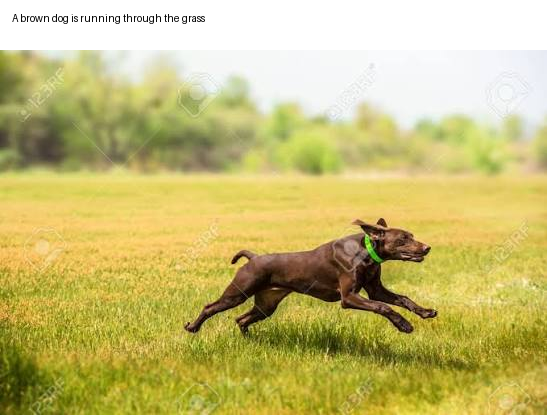

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [48]:

from google.colab import files

def add_caption_to_image(image, caption):
    image = image.convert("RGB")

    font_size = max(18, image.width // 35)
    padding = max(12, image.width // 60)
    max_width = image.width - 2 * padding

    try:
        font = ImageFont.truetype(
            "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf",
            font_size
        )
    except OSError:
        font = ImageFont.load_default()

    draw_helper = ImageDraw.Draw(image)
    lines = []
    current_line = ""

    for word in caption.split():
        candidate = (current_line + " " + word).strip()

        text_width = draw_helper.textbbox(
            (0, 0), candidate, font=font
        )[2]

        if text_width <= max_width:
            current_line = candidate
        else:
            if current_line:
                lines.append(current_line)
            current_line = word

    if current_line:
        lines.append(current_line)

    line_height = font_size + 8
    caption_height = 2 * padding + line_height * max(1, len(lines))

    result = Image.new(
        "RGB",
        (image.width, image.height + caption_height),
        "white"
    )

    result.paste(image, (0, caption_height))
    draw = ImageDraw.Draw(result)

    for i, line in enumerate(lines):
        draw.text(
            (padding, padding + i * line_height),
            line,
            fill="black",
            font=font
        )

    return result


uploaded = files.upload()

for filename in uploaded:
    try:
        image = Image.open(filename).convert("RGB")

        caption = generate_caption(image)

        output_image = add_caption_to_image(
            image,
            caption
        )

        print("Generated caption:", caption)
        display(output_image)

        output_name = (
            Path(filename).stem + "_captioned.png"
        )

        output_image.save(output_name)
        files.download(output_name)

    except Exception as error:
        print(f"Error processing {filename}: {error}")
